# Task B — XAA No-FT + **DVR Ablation** (Unified)

**Mục tiêu:** kiểm chứng xem hai thành phần lấy cảm hứng từ *Dual-guided Vision Refinement* (FashionERN) có cải thiện khả năng truy hồi so với **XAA No-FT Baseline** hay không:

| Experiment | `use_mr` | `use_sr` | Train trong notebook này |
|---|:-:|:-:|:-:|
| XAA No-FT Baseline | False | False | Không — chỉ load checkpoint/kết quả đã có để đối chiếu |
| `xaa_mr` — XAA + MR (Modifier-guided) | True | False | Có |
| `xaa_sr` — XAA + SR (Self-guided) | False | True | Có |
| `xaa_full_dvr` — XAA + MR → SR | True | True | Có |

**Kiểm soát biến:** cùng split CSV · cùng Frozen Fashion-CLIP features · cùng `XAA` cơ bản · cùng Multi-positive InfoNCE · cùng optimizer/scheduler/hyperparameters/seed/early-stopping · cùng checkpoint selection (**internal-val Global R@10**) · cùng query/gallery/metric khi final evaluation. *Chỉ* sự có mặt của MR/SR thay đổi.

**Không có:** fine-tuning, FT checkpoint/feature, TME, target alignment, auxiliary loss, global branch, kết quả XAA FT.

> ⚠️ **Lưu ý trung thực.** MR/SR ở đây là *thiết kế lấy cảm hứng từ FashionERN, được điều chỉnh cho chuỗi 50 image-token của XAA* — **không** phải implementation nguyên bản của FashionERN.
> Notebook này **chưa được chạy trên feature thật** khi tạo ra; mọi con số chỉ xuất hiện sau khi bạn chạy trên Colab. Không có metric/log nào được viết sẵn.

## 2. Environment Setup

In [ ]:
import os, sys, json, time, random, math, subprocess, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
try:
    import faiss
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"])
    import faiss

warnings.filterwarnings("ignore")
SEED = 42                                   # = baseline
def set_seed(s):                            # = baseline
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False

def check(cond, msg):                       # = baseline: dừng ngay với thông báo rõ ràng
    if not cond:
        raise ValueError("CHECK FAILED: " + msg)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
T_START = time.time()

Mounted at /content/drive
Device: cuda | Tesla T4


## 3. Common Configuration

Chỉ cần sửa **đường dẫn** và **`RUN_EXPERIMENTS`**. Mọi hyperparameter huấn luyện được copy từ baseline và được `assert` (mục 13 và mục 16) để tránh sửa nhầm.

* `RUN_EXPERIMENTS` — chọn biến thể cần train *trong phiên này*. Biến thể đã hoàn tất (có `metrics.json`) sẽ tự động được bỏ qua.
* `FORCE_RETRAIN` — `True` để xoá kết quả của **chỉ** các biến thể trong `RUN_EXPERIMENTS` và train lại.
* `RESUME` — tiếp tục từ `last_checkpoint.pt` (có đủ model/optimizer/scheduler/history/RNG state) nếu phiên trước bị ngắt.

In [ ]:
BASE        = "/content/drive/MyDrive/ĐATN/data/processed"
TEXT_DIR    = f"{BASE}/embeddings/text_features_taskb"       # text hidden/mask + master csv + *.npy ids
IMG_DIR     = f"{BASE}/embeddings/image_features_taskb"      # FROZEN reference hidden + target embeds
SPLIT_CSV_PATH = f"{TEXT_DIR}/FashionIQ_Task_B_Experiment_Split.csv"   # file split thống nhất (KHÔNG sửa)

# ---- baseline đã chạy (chỉ ĐỌC, không ghi đè) ----
BASELINE_DIR      = f"{BASE}/models/xaa_no_ft_unified"
BASELINE_CKPT     = f"{BASELINE_DIR}/xaa_no_ft_best.pt"
BASELINE_SUMMARY  = f"{BASELINE_DIR}/final_evaluation_summary.json"

# ---- output của notebook này: outputs/<experiment>/{best_checkpoint.pt, training_history.csv, metrics.json} ----
OUT_ROOT = f"{BASE}/models/xaa_dvr_ablation/outputs"

# tên file feature (giống baseline)
TEXT_HIDDEN_CANDIDATES = ["fashionclip_text_hidden_states.npy", "fashionclip_text_hidden_states-001.npy"]
TEXT_MASK_FILE = "fashionclip_text_attention_masks.npy"
REF_HIDDEN_FILE, REF_MAP_FILE = "reference_image_hidden_states.npy", "reference_id2idx.json"
TGT_EMBED_FILE, TGT_MAP_FILE  = "target_image_embeds.npy",         "target_id2idx.json"
IMG_META_FILE = "image_feature_metadata.json"                      # tuỳ chọn

USE_LOCAL_CACHE = True                      # copy .npy về đĩa local Colab để mmap nhanh (không ảnh hưởng kết quả)
CACHE_DIR = "/content/xaa_noft_cache"

# ảnh FashionIQ (tuỳ chọn, chỉ cho spot-check + visualization). Thư mục không tồn tại -> tự bỏ qua.
IMAGES_DIR = "/content/fashioniq_data/resized_images/resized_images"

# ---- điều khiển thí nghiệm ----
RUN_EXPERIMENTS = ["xaa_mr", "xaa_sr", "xaa_full_dvr"]   # đổi danh sách này để chạy từng biến thể riêng
FORCE_RETRAIN = False
RESUME = True

EXPERIMENTS = {
    "xaa_mr":       dict(use_mr=True,  use_sr=False, label="XAA + MR"),
    "xaa_sr":       dict(use_mr=False, use_sr=True,  label="XAA + SR"),
    "xaa_full_dvr": dict(use_mr=True,  use_sr=True,  label="XAA + Full DVR"),
}
check(all(e in EXPERIMENTS for e in RUN_EXPERIMENTS), f"RUN_EXPERIMENTS chứa tên lạ: {RUN_EXPERIMENTS}; hợp lệ: {list(EXPERIMENTS)}")
check(len(set(RUN_EXPERIMENTS)) == len(RUN_EXPERIMENTS), "RUN_EXPERIMENTS có tên trùng")

# ---- siêu tham số DVR (khai báo MỘT chỗ, dùng chung MR & SR để không thành biến gây nhiễu) ----
DVR_HIDDEN = 256      # chiều ẩn của MLP gate
DVR_ALPHA  = 1.0      # biên độ gate: g = 1 + alpha * tanh(G) ∈ (1-alpha, 1+alpha) = (0, 2); alpha CỐ ĐỊNH (không học)

# số lượng kỳ vọng từ file split thống nhất (chỉ dùng để assert — số liệu thật đọc từ CSV)
EXPECTED = dict(rows=24016, train=16204, internal_val=1796, final_test=5916, excluded_final_overlap=100,
                final_unique_targets=5903)
os.makedirs(OUT_ROOT, exist_ok=True)
FEATURE_SOURCE = dict(image_features="no_ft_frozen_fashion_clip", base_model="patrickjohncyh/fashion-clip",
                      text_dir=TEXT_DIR, img_dir=IMG_DIR, split_csv=os.path.basename(SPLIT_CSV_PATH))
print("RUN_EXPERIMENTS =", RUN_EXPERIMENTS, "| OUT_ROOT =", OUT_ROOT)

RUN_EXPERIMENTS = ['xaa_mr', 'xaa_sr', 'xaa_full_dvr'] | OUT_ROOT = /content/drive/MyDrive/ĐATN/data/processed/models/xaa_dvr_ablation/outputs


## 4. Load Unified Split

Đọc trực tiếp `experiment_split` (không `train_test_split` lại, không `reset_index`). Giữ **original row index** 0..N-1 để khớp thứ tự `.npy`. Số lượng đọc từ CSV rồi so với kỳ vọng bằng assertion.

In [ ]:
check(os.path.exists(SPLIT_CSV_PATH), f"Không thấy split CSV: {SPLIT_CSV_PATH}")
df = pd.read_csv(SPLIT_CSV_PATH)
check(isinstance(df.index, pd.RangeIndex) and df.index.start == 0 and df.index.step == 1,
      "Split CSV phải giữ original row order (RangeIndex 0..N-1)")
for c in ["category", "reference_image_id", "target_image_id", "modification_text", "official_split", "experiment_split"]:
    check(c in df.columns, f"Thiếu cột {c}. Cột hiện có: {list(df.columns)}")
df["reference_image_id"] = df["reference_image_id"].astype(str).str.strip()
df["target_image_id"]    = df["target_image_id"].astype(str).str.strip()
df["category"]           = df["category"].astype(str).str.strip().str.lower()
df["experiment_split"]   = df["experiment_split"].astype(str).str.strip()

vc = df["experiment_split"].value_counts().to_dict()
print(vc)
check(len(df) == EXPECTED["rows"], f"rows={len(df)}")
check(set(vc) == {"train", "internal_val", "final_test", "excluded_final_overlap"}, f"experiment_split values={set(vc)}")
for k in ["train", "internal_val", "final_test", "excluded_final_overlap"]:
    check(vc[k] == EXPECTED[k], f"{k}={vc[k]} (expected {EXPECTED[k]})")

tgt_by = {k: set(df.loc[df.experiment_split == k, "target_image_id"]) for k in vc}
check(len(tgt_by["train"] & tgt_by["internal_val"]) == 0, "train ∩ internal_val có chung target ID")
check(len(tgt_by["train"] & tgt_by["final_test"]) == 0,   "train ∩ final_test có chung target ID (leakage)")
check(len(tgt_by["internal_val"] & tgt_by["final_test"]) == 0, "internal_val ∩ final_test có chung target ID (leakage)")
check(len(tgt_by["final_test"]) == EXPECTED["final_unique_targets"], f"final_test unique targets={len(tgt_by['final_test'])}")
check(set(df.loc[df.experiment_split.isin(["train", "internal_val"]), "official_split"]) == {"train"}, "train/internal_val phải thuộc official train")
check(set(df.loc[df.experiment_split.isin(["final_test", "excluded_final_overlap"]), "official_split"]) == {"val"}, "final_test/excluded phải thuộc official val")
ex = tgt_by["excluded_final_overlap"]
check(len(ex & (tgt_by["train"] | tgt_by["internal_val"])) == len(ex), "excluded_final_overlap phải là target đã thấy ở train/internal_val")
print(f"[info] excluded_final_overlap: {len(ex)} target — KHÔNG tham gia final evaluation.")
SPLIT_SHA = hashlib.sha256(pd.util.hash_pandas_object(df[["reference_image_id","target_image_id","experiment_split"]], index=True).values.tobytes()).hexdigest()[:16]
print("split sha256[:16] =", SPLIT_SHA)
print(df.groupby(["experiment_split", "category"]).agg(n=("target_image_id", "size"), uniq_targets=("target_image_id", "nunique")))

{'train': 16204, 'final_test': 5916, 'internal_val': 1796, 'excluded_final_overlap': 100}
[info] excluded_final_overlap: 100 target — KHÔNG tham gia final evaluation.
split sha256[:16] = 6a6e18f370f264b7
                                    n  uniq_targets
experiment_split       category                    
excluded_final_overlap shirt       51            51
                       toptee      49            49
final_test             dress     2017          2017
                       shirt     1987          1987
                       toptee    1912          1912
internal_val           dress      598           598
                       shirt      599           599
                       toptee     599           599
train                  dress     5387          5387
                       shirt     5389          5389
                       toptee    5428          5428


## 5. Load Frozen Fashion-CLIP Features

Dùng đúng bộ feature pretrained của baseline (không extract lại, không đổi checkpoint/tokenizer/preprocessing). Chỉ các chiều **bắt buộc bởi kiến trúc** (50×768, 77×512, 512) được assert; kích thước thực tế được in ra.

In [ ]:
os.makedirs(CACHE_DIR, exist_ok=True)
def stage(path):
    check(os.path.exists(path), f"Không thấy file: {path}")
    if not USE_LOCAL_CACHE:
        return path
    dst = os.path.join(CACHE_DIR, os.path.basename(path))
    if not (os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(path)):
        print("copy ->", dst); shutil.copy(path, dst)
    return dst

text_hidden_path = next((f"{TEXT_DIR}/{n}" for n in TEXT_HIDDEN_CANDIDATES if os.path.exists(f"{TEXT_DIR}/{n}")), None)
check(text_hidden_path is not None, f"Không thấy text hidden states trong {TEXT_DIR}: {TEXT_HIDDEN_CANDIDATES}")

text_hidden = np.load(stage(text_hidden_path), mmap_mode="r")
text_mask   = np.load(stage(f"{TEXT_DIR}/{TEXT_MASK_FILE}"), mmap_mode="r")
ref_hidden  = np.load(stage(f"{IMG_DIR}/{REF_HIDDEN_FILE}"), mmap_mode="r")
check(os.path.exists(f"{IMG_DIR}/{TGT_EMBED_FILE}"), f"Không thấy {TGT_EMBED_FILE}")
tgt_embeds  = np.load(f"{IMG_DIR}/{TGT_EMBED_FILE}").astype(np.float32)
for p in [f"{IMG_DIR}/{REF_MAP_FILE}", f"{IMG_DIR}/{TGT_MAP_FILE}"]:
    check(os.path.exists(p), f"Không thấy file mapping: {p}")
with open(f"{IMG_DIR}/{REF_MAP_FILE}") as f: reference_id2idx = json.load(f)
with open(f"{IMG_DIR}/{TGT_MAP_FILE}") as f: target_id2idx   = json.load(f)

print("text_hidden:", text_hidden.shape, "| text_mask:", text_mask.shape)
print("ref_hidden :", ref_hidden.shape,  "| tgt_embeds:", tgt_embeds.shape)
print("n_ref ids  :", len(reference_id2idx), "| n_tgt ids:", len(target_id2idx))

copy -> /content/xaa_noft_cache/fashionclip_text_hidden_states.npy
copy -> /content/xaa_noft_cache/fashionclip_text_attention_masks.npy
copy -> /content/xaa_noft_cache/reference_image_hidden_states.npy
text_hidden: (24016, 77, 512) | text_mask: (24016, 77)
ref_hidden : (16787, 50, 768) | tgt_embeds: (23742, 512)
n_ref ids  : 16787 | n_tgt ids: 23742


In [ ]:
# ===== SANITY CHECKS: shape / mapping / NaN-Inf / alignment (= baseline) =====
def finite_chunked(arr, step=2000):
    return all(np.isfinite(np.asarray(arr[s:s+step])).all() for s in range(0, arr.shape[0], step))

check(text_hidden.shape == (len(df), 77, 512), f"text_hidden {text_hidden.shape} vs CSV rows {len(df)}")
check(text_mask.shape == (len(df), 77), f"text_mask {text_mask.shape}")
check(ref_hidden.ndim == 3 and ref_hidden.shape[1:] == (50, 768), f"ref_hidden shape {ref_hidden.shape}")
check(tgt_embeds.ndim == 2 and tgt_embeds.shape[1] == 512, f"tgt_embeds shape {tgt_embeds.shape}")

for name, mp, n in [("reference", reference_id2idx, ref_hidden.shape[0]), ("target", target_id2idx, tgt_embeds.shape[0])]:
    check(len(mp) == n, f"len({name}_id2idx)={len(mp)} != {n}")
    check(sorted(mp.values()) == list(range(n)), f"{name}_id2idx không phải hoán vị 0..{n-1}")
check(all(i in reference_id2idx for i in df["reference_image_id"]), "Thiếu mapping reference")
check(all(i in target_id2idx    for i in df["target_image_id"]),    "Thiếu mapping target")
check(len(reference_id2idx) == df["reference_image_id"].nunique(), "reference map không khớp số reference unique trong CSV")
check(len(target_id2idx)    == df["target_image_id"].nunique(),    "target map không khớp số target unique trong CSV")

check(finite_chunked(text_hidden), "text_hidden có NaN/Inf")
check(finite_chunked(text_mask),   "text_mask có NaN/Inf")
check(finite_chunked(ref_hidden),  "ref_hidden có NaN/Inf")
check(np.isfinite(tgt_embeds).all(), "tgt_embeds có NaN/Inf")
_n = np.linalg.norm(tgt_embeds, axis=1)
check(abs(_n.mean() - 1.0) < 1e-3, f"target norm mean={_n.mean():.5f}")
check(set(np.unique(np.asarray(text_mask[:2000]))) <= {0.0, 1.0}, "text_mask không phải nhị phân")

def _npy(name):
    p = f"{TEXT_DIR}/{name}"
    return np.load(p, allow_pickle=True) if os.path.exists(p) else None
for fname, col in [("reference_image_ids.npy", "reference_image_id"), ("target_image_ids.npy", "target_image_id")]:
    a = _npy(fname)
    if a is None: print(f"[warn] không có {fname} -> bỏ qua kiểm tra này"); continue
    check(np.array_equal(np.array([str(x).strip() for x in a]), df[col].values), f"{fname} != thứ tự split CSV")
a = _npy("category.npy")
if a is not None: check(np.array_equal(np.array([str(x).strip().lower() for x in a]), df["category"].values), "category.npy != split CSV")
a = _npy("split.npy")
if a is not None: check(np.array_equal(np.array([str(x).strip().lower() for x in a]), df["official_split"].str.lower().values), "split.npy != official_split")
mp = f"{TEXT_DIR}/fashioniq_taskb_master.csv"
if os.path.exists(mp):
    m = pd.read_csv(mp)
    check(len(m) == len(df), "master csv khác số dòng với split csv")
    for c in ["reference_image_id", "target_image_id", "modification_text"]:
        check((m[c].astype(str).str.strip().values == df[c].astype(str).str.strip().values).all(), f"master csv cột {c} lệch thứ tự so với split csv")
    print("master CSV (nguồn text embedding) khớp từng dòng với split CSV.")
else:
    print("[warn] không có master csv -> chỉ kiểm tra qua *.npy ids")

TGT_MAP_SHA = hashlib.sha256(json.dumps(target_id2idx, sort_keys=True).encode()).hexdigest()[:16]
print("OK. target norm mean = %.6f | target_id2idx sha256[:16] = %s" % (_n.mean(), TGT_MAP_SHA))

[warn] không có master csv -> chỉ kiểm tra qua *.npy ids
OK. target norm mean = 1.000000 | target_id2idx sha256[:16] = 68808a8fbeee4998


### 5b. Guard: chắc chắn đây là feature **No-FT**

1. Đường dẫn không chứa dấu hiệu FT. 2. Metadata (nếu có) không có `checkpoint_filename`. 3. *(Tuỳ chọn)* spot-check: tính lại vài ảnh bằng `patrickjohncyh/fashion-clip` gốc và so với `.npy`.

In [ ]:
FT_MARKERS = ["branch_a_ft", "xaa_branch_a_ft", "finetune", "fine_tune", "fine-tune"]
for p in [TEXT_DIR, IMG_DIR, text_hidden_path, SPLIT_CSV_PATH, BASELINE_DIR, OUT_ROOT]:
    check(not any(mk in str(p).lower() for mk in FT_MARKERS), f"Đường dẫn có dấu hiệu FT: {p}")

meta_path = f"{IMG_DIR}/{IMG_META_FILE}"
if os.path.exists(meta_path):
    with open(meta_path) as f: img_meta = json.load(f)
    check(img_meta.get("base_model", "patrickjohncyh/fashion-clip") == "patrickjohncyh/fashion-clip", f"base_model={img_meta.get('base_model')}")
    check(not img_meta.get("checkpoint_filename"), f"Metadata có checkpoint_filename={img_meta.get('checkpoint_filename')} -> feature FT!")
    print("image_feature_metadata:", img_meta)
else:
    print("[info] không có image_feature_metadata.json (bình thường với pipeline No-FT).")

SPOT = {"done": False}
if IMAGES_DIR and os.path.isdir(IMAGES_DIR):
    from transformers import CLIPModel, CLIPImageProcessor
    from PIL import Image
    _name = "patrickjohncyh/fashion-clip"
    _proc = CLIPImageProcessor.from_pretrained(_name)
    _clip = CLIPModel.from_pretrained(_name).to(device).eval()
    _rng = np.random.RandomState(0)
    _t_ids = list(_rng.choice(list(target_id2idx), 24, replace=False))
    _r_ids = list(_rng.choice(list(reference_id2idx), 12, replace=False))
    def _px(ids): return _proc(images=[Image.open(f"{IMAGES_DIR}/{i}.jpg").convert("RGB") for i in ids], return_tensors="pt")["pixel_values"].to(device)
    with torch.no_grad():
        _o = _clip.get_image_features(pixel_values=_px(_t_ids))
        _o = _o.pooler_output if hasattr(_o, "pooler_output") else _o
        _o = F.normalize(_o, dim=-1).cpu().numpy()
        _h = _clip.vision_model(pixel_values=_px(_r_ids)).last_hidden_state.cpu().numpy()
    _cos_t = (_o * tgt_embeds[[target_id2idx[i] for i in _t_ids]]).sum(1)
    _a = _h.reshape(len(_r_ids), -1); _b = np.stack([np.asarray(ref_hidden[reference_id2idx[i]]) for i in _r_ids]).reshape(len(_r_ids), -1)
    _cos_r = (_a * _b).sum(1) / (np.linalg.norm(_a, axis=1) * np.linalg.norm(_b, axis=1))
    print(f"spot-check target cos: min={_cos_t.min():.5f} | reference cos: min={_cos_r.min():.5f}")
    check(_cos_t.min() > 0.999 and _cos_r.min() > 0.999, "Feature trong .npy KHÔNG khớp pretrained Fashion-CLIP gốc!")
    SPOT = {"done": True, "target_cos_min": float(_cos_t.min()), "ref_cos_min": float(_cos_r.min())}
    del _clip; torch.cuda.empty_cache()
else:
    print("[info] IMAGES_DIR không tồn tại -> bỏ qua spot-check bằng model gốc.")

[info] không có image_feature_metadata.json (bình thường với pipeline No-FT).
[info] IMAGES_DIR không tồn tại -> bỏ qua spot-check bằng model gốc.


## 6. Dataset and DataLoader  (= baseline, trả thêm `target_idx`)

In [ ]:
class FusionTripletDataset(Dataset):
    def __init__(self, rows):
        self.rows = np.asarray(rows)                      # ORIGINAL row indices
        self.ref_ids = df["reference_image_id"].values
        self.tgt_ids = df["target_image_id"].values
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        rid, tid = self.ref_ids[r], self.tgt_ids[r]
        t_idx = target_id2idx[tid]
        return {
            "text_hidden":      torch.from_numpy(np.array(text_hidden[r], dtype=np.float32)),   # [77,512]
            "text_mask":        torch.from_numpy(np.array(text_mask[r],   dtype=np.float32)),   # [77]
            "reference_hidden": torch.from_numpy(np.array(ref_hidden[reference_id2idx[rid]], dtype=np.float32)),  # [50,768]
            "target_embed":     torch.from_numpy(tgt_embeds[t_idx]),                            # [512]
            "target_idx":       t_idx,
            "target_image_id":  tid,
        }

BATCH_SIZE, NUM_WORKERS = 128, 2
train_rows = np.where(df.experiment_split == "train")[0]
iv_rows    = np.where(df.experiment_split == "internal_val")[0]
check(len(train_rows) == EXPECTED["train"] and len(iv_rows) == EXPECTED["internal_val"], "số dòng train/internal_val sai")
train_ds, iv_ds = FusionTripletDataset(train_rows), FusionTripletDataset(iv_rows)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                          persistent_workers=NUM_WORKERS > 0)
iv_loader = DataLoader(iv_ds, batch_size=256, shuffle=False, num_workers=NUM_WORKERS,
                       pin_memory=(device.type == "cuda"))
b = next(iter(train_loader))
print({k: (tuple(v.shape) if torch.is_tensor(v) else type(v).__name__) for k, v in b.items()})
print("train batches:", len(train_loader), "| iv batches:", len(iv_loader))

{'text_hidden': (128, 77, 512), 'text_mask': (128, 77), 'reference_hidden': (128, 50, 768), 'target_embed': (128, 512), 'target_idx': (128,), 'target_image_id': 'list'}
train batches: 126 | iv batches: 8


## 7. XAA Baseline Architecture  (copy nguyên từ baseline)

`Linear(768→512) → LayerNorm → MHA(8 heads, dropout 0.1, Q=text, K=V=ref) → residual + LayerNorm → masked mean → L2`.

Class này giữ **nguyên văn** để (i) làm tham chiếu cho unit test tương đương, (ii) load checkpoint baseline khi đối chiếu.

In [ ]:
class XAAFusionModule(nn.Module):
    def __init__(self, text_dim=512, img_dim=768, embed_dim=512, num_heads=8, dropout=0.1):
        super().__init__()
        self.ref_proj = nn.Linear(img_dim, embed_dim)
        self.ref_ln   = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads,
                                          batch_first=True, dropout=dropout)
        self.out_ln = nn.LayerNorm(embed_dim)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def forward(self, text_hidden, text_mask, reference_hidden):
        ref = self.ref_ln(self.ref_proj(reference_hidden))              # [B,50,512]
        att, _ = self.attn(query=text_hidden, key=ref, value=ref)       # [B,77,512]
        x = self.out_ln(text_hidden + att)                              # residual + LN
        m = text_mask.unsqueeze(-1)                                     # [B,77,1]
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1.0)               # masked mean
        return F.normalize(pooled, dim=-1)                              # [B,512]

def state_hash(m, exclude_prefixes=()):
    # = hash của baseline khi exclude_prefixes=(); với XAADVR bỏ qua tham số MR/SR để so phần XAA chung
    h = hashlib.sha256()
    for k, v in m.state_dict().items():
        if any(k.startswith(p) for p in exclude_prefixes): continue
        h.update(k.encode()); h.update(v.detach().cpu().numpy().tobytes())
    return h.hexdigest()[:16]

_EXPECTED_PARAMS = {"logit_scale": (), "ref_proj.weight": (512, 768), "ref_proj.bias": (512,),
    "ref_ln.weight": (512,), "ref_ln.bias": (512,), "attn.in_proj_weight": (1536, 512), "attn.in_proj_bias": (1536,),
    "attn.out_proj.weight": (512, 512), "attn.out_proj.bias": (512,), "out_ln.weight": (512,), "out_ln.bias": (512,)}
_m = XAAFusionModule()
check({k: tuple(v.shape) for k, v in _m.state_dict().items()} == _EXPECTED_PARAMS, "XAA param shapes khác baseline")
check(_m.attn.num_heads == 8 and abs(_m.attn.dropout - 0.1) < 1e-9, "XAA heads/dropout khác baseline")
print("XAA baseline params: %.2fM" % (sum(p.numel() for p in _m.parameters()) / 1e6)); del _m

XAA baseline params: 1.45M


## 8. Modifier-guided Refinement (MR)

Dùng **modification text** để điều chỉnh mức đóng góp của từng image token (sau Image Projection):

* Modifier representation: `t = masked_mean(text_hidden, text_mask)` — padding **không** tham gia.
* Gate: `G(V,T) = Linear_{h→1}( GELU( W_v·V_i + W_t·t ) )`  → một scalar cho mỗi token.
* Refinement: **`V_MR = V · (1 + α·tanh(G(V,T)))`** với `α = DVR_ALPHA = 1.0` *cố định* ⇒ hệ số nhân ∈ (0, 2).
* **Gần identity lúc khởi tạo:** lớp `Linear_{h→1}` cuối được khởi tạo bằng 0 ⇒ `tanh(0)=0` ⇒ `V_MR = V` đúng từng bit. (`α` không học vì nếu `α=0` và lớp cuối `=0` thì gradient bằng 0 mọi nơi.)
* Shape vào/ra: `[B,50,512]`.

In [ ]:
class ModifierGuidedRefinement(nn.Module):
    def __init__(self, dim=512, hidden=DVR_HIDDEN, alpha=DVR_ALPHA):
        super().__init__()
        self.alpha = float(alpha)
        self.v_proj = nn.Linear(dim, hidden)       # W_v
        self.t_proj = nn.Linear(dim, hidden)       # W_t
        self.act = nn.GELU()
        self.out = nn.Linear(hidden, 1)            # gate head
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)   # identity tại khởi tạo

    def forward(self, v, text_hidden, text_mask):
        # v: [B,N,D] | text_hidden: [B,L,D] | text_mask: [B,L] (1 = token thật)
        m = text_mask.unsqueeze(-1).to(text_hidden.dtype)
        t = (text_hidden * m).sum(1) / m.sum(1).clamp(min=1.0)                  # masked mean, bỏ padding   [B,D]
        h = self.act(self.v_proj(v) + self.t_proj(t).unsqueeze(1))              # [B,N,hidden]
        gate = 1.0 + self.alpha * torch.tanh(self.out(h).squeeze(-1))          # [B,N]  ∈ (1-α, 1+α)
        return v * gate.unsqueeze(-1), gate

## 9. Self-guided Refinement (SR)

Tinh chỉnh image token chỉ dựa trên **nội dung thị giác nội tại** (không dùng text):

* Ngữ cảnh toàn ảnh: `c = mean_i(V_i)`.
* Importance score: `s_i = Linear_{h→1}( GELU( W_v·V_i + W_c·c ) )`.
* **`V_SR = V · (1 + α·tanh(s))`**, cùng `α`, `hidden`, và cách khởi tạo identity như MR ⇒ MR và SR chỉ khác nhau ở *nguồn hướng dẫn* (text vs ảnh).
* Shape `[B,50,512]`; gradient truyền bình thường (không `detach`).

In [ ]:
class SelfGuidedRefinement(nn.Module):
    def __init__(self, dim=512, hidden=DVR_HIDDEN, alpha=DVR_ALPHA):
        super().__init__()
        self.alpha = float(alpha)
        self.v_proj = nn.Linear(dim, hidden)       # W_v
        self.c_proj = nn.Linear(dim, hidden)       # W_c (ngữ cảnh thị giác toàn ảnh)
        self.act = nn.GELU()
        self.out = nn.Linear(hidden, 1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, v):                           # CHỈ nhận image tokens — không có đường vào cho text
        ctx = v.mean(dim=1)                                                     # [B,D]
        h = self.act(self.v_proj(v) + self.c_proj(ctx).unsqueeze(1))            # [B,N,hidden]
        gate = 1.0 + self.alpha * torch.tanh(self.out(h).squeeze(-1))          # [B,N]
        return v * gate.unsqueeze(-1), gate

## 10. Configurable XAA-DVR

`Image Projection (Linear+LN) → [MR] → [SR] → XAA Fusion (cross-attention, giữ nguyên)`.

* Các tham số XAA được tạo **cùng thứ tự** như `XAAFusionModule` nên cùng seed ⇒ cùng giá trị khởi tạo.
* MR/SR được tạo **sau** và RNG toàn cục được **khôi phục** ngay sau đó ⇒ dòng ngẫu nhiên (shuffle, dropout) của các biến thể không bị lệch bởi việc có/không có MR/SR.
* Khi tắt, `self.mr/self.sr = None` ⇒ `state_dict` **không có** key `mr.*`/`sr.*` ⇒ khớp chính xác checkpoint baseline.
* `return_gates=True` trả thêm `{"mr": [B,50], "sr": [B,50]}` (không detach; việc `detach()` do nơi phân tích tự làm).

In [ ]:
class XAADVR(nn.Module):
    def __init__(self, use_mr=False, use_sr=False, text_dim=512, img_dim=768, embed_dim=512, num_heads=8,
                 dropout=0.1, dvr_hidden=DVR_HIDDEN, dvr_alpha=DVR_ALPHA):
        super().__init__()
        self.use_mr, self.use_sr = bool(use_mr), bool(use_sr)
        # --- XAA cơ bản: cùng thứ tự khởi tạo với XAAFusionModule ---
        self.ref_proj = nn.Linear(img_dim, embed_dim)
        self.ref_ln   = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True, dropout=dropout)
        self.out_ln = nn.LayerNorm(embed_dim)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
        # --- DVR: tạo sau, rồi trả RNG về trạng thái ngay sau khi tạo XAA ---
        _rng = torch.get_rng_state()
        self.mr = ModifierGuidedRefinement(embed_dim, dvr_hidden, dvr_alpha) if self.use_mr else None
        self.sr = SelfGuidedRefinement(embed_dim, dvr_hidden, dvr_alpha) if self.use_sr else None
        torch.set_rng_state(_rng)

    def forward(self, text_hidden, text_mask, reference_hidden, return_gates=False):
        ref = self.ref_ln(self.ref_proj(reference_hidden))              # Image Projection  [B,50,512]
        gates = {}
        if self.mr is not None:
            ref, gates["mr"] = self.mr(ref, text_hidden, text_mask)    # MR
        if self.sr is not None:
            ref, gates["sr"] = self.sr(ref)                            # SR (sau MR)
        att, _ = self.attn(query=text_hidden, key=ref, value=ref)       # XAA không đổi
        x = self.out_ln(text_hidden + att)
        m = text_mask.unsqueeze(-1)
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1.0)
        out = F.normalize(pooled, dim=-1)
        return (out, gates) if return_gates else out

def n_params(m): return sum(p.numel() for p in m.parameters())
_ref_n = n_params(XAAFusionModule())
for _n_, _s_ in {"baseline-equivalent": (False, False), **{k: (v["use_mr"], v["use_sr"]) for k, v in EXPERIMENTS.items()}}.items():
    _mm = XAADVR(*_s_); print(f"{_n_:22s} params={n_params(_mm):>9,d}  (+{n_params(_mm)-_ref_n:,d} vs XAA)")

baseline-equivalent    params=1,446,401  (+0 vs XAA)
xaa_mr                 params=1,709,314  (+262,913 vs XAA)
xaa_sr                 params=1,709,314  (+262,913 vs XAA)
xaa_full_dvr           params=1,972,227  (+525,826 vs XAA)


## 11. Multi-positive InfoNCE  (copy nguyên từ baseline)

Positive mask theo `target_idx` (query cùng target là positive của nhau, không bị coi là negative); loss đối xứng `comp→tgt` & `tgt→comp`; `logit_scale` học được, clamp `[0, ln 100]` như baseline. Không auxiliary loss.

In [ ]:
def multi_positive_infonce(comp, tgt, target_idx, logit_scale):
    comp = F.normalize(comp.float(), dim=-1)
    tgt  = F.normalize(tgt.float(),  dim=-1)
    logits = comp @ tgt.T * logit_scale.exp()                           # [B,B]
    pos = (target_idx[:, None] == target_idx[None, :]).float()          # positive_mask[i,j]
    def one_way(lg, p):
        logp = F.log_softmax(lg, dim=1)
        return (-(logp * p).sum(1) / p.sum(1).clamp(min=1.0)).mean()
    return 0.5 * (one_way(logits, pos) + one_way(logits.T, pos.T))      # comp->tgt & tgt->comp

## 12. Unit Tests and Sanity Checks

Chạy trên tensor tổng hợp (CPU, không dùng feature thật, không đụng RNG toàn cục — RNG được lưu/khôi phục). **Mọi test phải qua trước khi train.**

| # | Kiểm tra |
|---|---|
| T1 | MR/SR/Full giữ nguyên shape `[B,50,512]` |
| T2 | MR/SR **identity** lúc khởi tạo (gate = 1 chính xác) |
| T3 | 4 cấu hình forward OK, output `[B,512]`, L2-norm = 1, hữu hạn |
| T4 | **XAADVR(False,False) ≡ XAAFusionModule** (cùng init hash, cùng state_dict keys, cùng output); Full DVR lúc init cũng trùng baseline (vì identity) |
| T5 | MR **không dùng padding** của text |
| T6 | Gradient chảy tới MR/SR/XAA, kể cả gate head khởi tạo bằng 0 |
| T7 | SR không có đường vào cho text |
| T8 | InfoNCE: target duy nhất = InfoNCE chuẩn; nhiều query chung target; hữu hạn; backward OK |

In [ ]:
import inspect, copy

def run_unit_tests():
    _cpu_state = torch.get_rng_state()
    try:
        g = torch.Generator().manual_seed(123)
        B = 6
        V  = torch.randn(B, 50, 512, generator=g)
        TH = torch.randn(B, 77, 512, generator=g)
        TM = torch.zeros(B, 77);
        for i in range(B): TM[i, : 5 + i] = 1.0
        RH = torch.randn(B, 50, 768, generator=g)

        # T1 ---------------------------------------------------------------
        set_seed(SEED); mr = ModifierGuidedRefinement(); sr = SelfGuidedRefinement()
        o1, g1 = mr(V, TH, TM); o2, g2 = sr(V)
        check(o1.shape == V.shape == o2.shape == (B, 50, 512), "T1: shape MR/SR sai")
        check(g1.shape == g2.shape == (B, 50), "T1: shape gate sai")
        # T2 ---------------------------------------------------------------
        check(torch.equal(o1, V) and torch.equal(o2, V), "T2: MR/SR không phải identity lúc init")
        check(torch.equal(g1, torch.ones_like(g1)) and torch.equal(g2, torch.ones_like(g2)), "T2: gate init != 1")
        # T3 ---------------------------------------------------------------
        for nm, (a, b_) in {"base": (False, False), "mr": (True, False), "sr": (False, True), "full": (True, True)}.items():
            set_seed(SEED); m = XAADVR(a, b_).eval()
            out, gt = m(TH, TM, RH, return_gates=True)
            check(out.shape == (B, 512) and torch.isfinite(out).all(), f"T3[{nm}]: output sai/NaN")
            check(torch.allclose(out.norm(dim=-1), torch.ones(B), atol=1e-5), f"T3[{nm}]: không L2-normalized")
            check(set(gt) == ({"mr"} if a else set()) | ({"sr"} if b_ else set()), f"T3[{nm}]: gates sai {set(gt)}")
        # T4 ---------------------------------------------------------------
        set_seed(SEED); base = XAAFusionModule().eval()
        set_seed(SEED); off  = XAADVR(False, False).eval()
        set_seed(SEED); full = XAADVR(True, True).eval()
        check(list(base.state_dict().keys()) == list(off.state_dict().keys()), "T4: state_dict keys của XAADVR(off) khác baseline")
        check(state_hash(base) == state_hash(off), "T4: init hash XAADVR(off) != baseline")
        check(state_hash(base) == state_hash(full, ("mr.", "sr.")), "T4: phần XAA của Full DVR khác init baseline")
        with torch.no_grad():
            ob, oo, of_ = base(TH, TM, RH), off(TH, TM, RH), full(TH, TM, RH)
        check(torch.allclose(ob, oo, atol=1e-6), "T4: output XAADVR(off) != baseline")
        check(torch.allclose(ob, of_, atol=1e-6), "T4: Full DVR lúc init (identity) != baseline")
        off2 = XAADVR(False, False).eval(); off2.load_state_dict(base.state_dict(), strict=True)   # load ckpt baseline strict
        with torch.no_grad(): check(torch.allclose(ob, off2(TH, TM, RH), atol=1e-6), "T4: sau load_state_dict output khác")
        # T5 ---------------------------------------------------------------
        mr2 = ModifierGuidedRefinement(); nn.init.normal_(mr2.out.weight, std=0.05); nn.init.normal_(mr2.out.bias, std=0.05)
        TH_alt = TH.clone(); TH_alt[TM == 0] = torch.randn_like(TH_alt[TM == 0]) * 10     # đổi toàn bộ vị trí PADDING
        ga, gb = mr2(V, TH, TM)[1], mr2(V, TH_alt, TM)[1]
        check(torch.allclose(ga, gb, atol=1e-6), "T5: MR bị ảnh hưởng bởi padding")
        TH_alt2 = TH.clone(); TH_alt2[TM == 1] += 1.0                                      # đổi token THẬT -> gate phải đổi
        check(not torch.allclose(ga, mr2(V, TH_alt2, TM)[1], atol=1e-6), "T5: MR không phản ứng với text thật (gate vô dụng)")
        check((ga - 1).abs().max() > 1e-3 and ga.min() > 0 and ga.max() < 2, "T5: gate ngoài (0,2) hoặc không thay đổi")
        # T6 ---------------------------------------------------------------
        set_seed(SEED); m = XAADVR(True, True).train()
        tgt = F.normalize(torch.randn(B, 512, generator=g), dim=-1); tidx = torch.arange(B)
        loss = multi_positive_infonce(m(TH, TM, RH), tgt, tidx, m.logit_scale); loss.backward()
        check(m.mr.out.weight.grad is not None and m.mr.out.weight.grad.abs().sum() > 0, "T6: gate head MR không nhận gradient lúc init")
        check(m.sr.out.weight.grad is not None and m.sr.out.weight.grad.abs().sum() > 0, "T6: gate head SR không nhận gradient lúc init")
        check(m.ref_proj.weight.grad.abs().sum() > 0, "T6: ref_proj không nhận gradient")
        m2 = XAADVR(True, True).train()
        for mod in (m2.mr, m2.sr): nn.init.normal_(mod.out.weight, std=0.2)             # phá zero-init để kiểm tra mọi lớp nhận grad
        loss = multi_positive_infonce(m2(TH, TM, RH), tgt, tidx, m2.logit_scale); loss.backward()
        for nm_, p_ in m2.named_parameters():
            check(p_.grad is not None and torch.isfinite(p_.grad).all() and p_.grad.abs().sum() > 0, f"T6: {nm_} không có gradient hợp lệ")
        # T7 ---------------------------------------------------------------
        check(list(inspect.signature(SelfGuidedRefinement.forward).parameters) == ["self", "v"], "T7: SR.forward nhận input ngoài image tokens")
        # T8 ---------------------------------------------------------------
        s = torch.tensor(math.log(1 / 0.07)); c, t = torch.randn(8, 512, generator=g), torch.randn(8, 512, generator=g)
        lg = F.normalize(c, dim=-1) @ F.normalize(t, dim=-1).T * s.exp(); lab = torch.arange(8)
        std = 0.5 * (F.cross_entropy(lg, lab) + F.cross_entropy(lg.T, lab))
        check(abs(float(multi_positive_infonce(c, t, torch.arange(8), s)) - float(std)) < 1e-5, "T8: != InfoNCE chuẩn khi target duy nhất")
        c2 = c.clone().requires_grad_(True); ls = nn.Parameter(s.clone())
        l_dup = multi_positive_infonce(c2, t, torch.tensor([1, 1, 1, 2, 3, 3, 4, 5]), ls)
        check(torch.isfinite(l_dup).item(), "T8: loss nhiều positive không hữu hạn")
        l_dup.backward(); check(c2.grad is not None and torch.isfinite(c2.grad).all() and ls.grad is not None, "T8: backward lỗi")
        l_all = multi_positive_infonce(c, t, torch.zeros(8, dtype=torch.long), s)             # mọi query cùng target
        check(torch.isfinite(l_all).item(), "T8: loss khi mọi target trùng không hữu hạn")
        print("ALL UNIT TESTS PASSED (T1–T8).")
    finally:
        torch.set_rng_state(_cpu_state)

run_unit_tests()
set_seed(SEED)
print("Backbone: Fashion-CLIP KHÔNG được load trong training — feature offline; chỉ XAA/MR/SR có tham số học => backbone frozen theo cấu trúc.")

ALL UNIT TESTS PASSED (T1–T8).
Backbone: Fashion-CLIP KHÔNG được load trong training — feature offline; chỉ XAA/MR/SR có tham số học => backbone frozen theo cấu trúc.


## 13. Training and Validation — Configuration  (copy từ baseline; được `assert` khớp)

Mọi biến thể dùng **đúng một** bộ hyperparameter này. Nếu baseline checkpoint tồn tại, config của nó cũng được đối chiếu ở mục 16b.

In [ ]:
BB_REFERENCE = dict(batch_size=128, lr=3e-4, weight_decay=0.01, max_epochs=40, eval_every=2, patience=5,
                    early_stop_metric="R@10", grad_clip=1.0, warmup_ratio=0.05, seed=42, embed_dim=512,
                    num_heads=8, attn_dropout=0.1, logit_scale_init=math.log(1 / 0.07))
CONFIG = dict(batch_size=BATCH_SIZE, lr=3e-4, weight_decay=0.01, max_epochs=40, eval_every=2,
    patience=5,   # đếm theo số lần eval không cải thiện (5 eval = 10 epoch)
    early_stop_metric="R@10", grad_clip=1.0, warmup_ratio=0.05,
    seed=SEED, embed_dim=512, num_heads=8, attn_dropout=0.1, logit_scale_init=math.log(1 / 0.07),
    image_features="no_ft_frozen_fashion_clip", n_train=len(train_rows), n_internal_val=len(iv_rows),
    n_final_test=int((df.experiment_split == "final_test").sum()))
for k, v in BB_REFERENCE.items():
    check(CONFIG[k] == v, f"CONFIG[{k}]={CONFIG[k]} khác baseline ({v})")
LOGIT_MAX = math.log(100.0)
KS = (1, 5, 10, 50)

# ---- internal-val gallery (= baseline): unique target của internal_val ----
iv_target_ids = df.loc[iv_rows, "target_image_id"].values
gallery_ids = list(pd.unique(iv_target_ids))
gallery_pos = {tid: i for i, tid in enumerate(gallery_ids)}
gallery_embeds = np.ascontiguousarray(np.stack([tgt_embeds[target_id2idx[t]] for t in gallery_ids]).astype(np.float32))
faiss.normalize_L2(gallery_embeds)
gallery_index = faiss.IndexFlatIP(gallery_embeds.shape[1]); gallery_index.add(gallery_embeds)
iv_gt_pos = np.array([gallery_pos[t] for t in iv_target_ids])
print("Internal-val gallery:", gallery_embeds.shape, "| queries:", len(iv_gt_pos))

@torch.no_grad()
def evaluate(model):                                         # = baseline (internal-val Global Recall@K)
    model.eval()
    qs = []
    for b in iv_loader:
        qs.append(model(b["text_hidden"].to(device), b["text_mask"].to(device),
                        b["reference_hidden"].to(device)).float().cpu().numpy())
    q = np.ascontiguousarray(np.concatenate(qs).astype(np.float32))
    faiss.normalize_L2(q)
    kmax = min(max(KS), gallery_index.ntotal)
    _, I = gallery_index.search(q, kmax)
    hit = (I == iv_gt_pos[:, None])
    return {f"R@{k}": float(hit[:, :min(k, kmax)].any(axis=1).mean() * 100) for k in KS}

def make_optim(model):                                       # = baseline
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    total_steps  = CONFIG["max_epochs"] * len(train_loader)
    warmup_steps = max(1, int(CONFIG["warmup_ratio"] * total_steps))
    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * p))
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda), total_steps, warmup_steps

def build_model(spec):
    set_seed(SEED)                                           # cùng seed => cùng init phần XAA ở mọi biến thể
    return XAADVR(use_mr=spec["use_mr"], use_sr=spec["use_sr"]).to(device)
print("total_steps:", CONFIG["max_epochs"] * len(train_loader), "| CONFIG:", CONFIG)

Internal-val gallery: (1784, 512) | queries: 1796
total_steps: 5040 | CONFIG: {'batch_size': 128, 'lr': 0.0003, 'weight_decay': 0.01, 'max_epochs': 40, 'eval_every': 2, 'patience': 5, 'early_stop_metric': 'R@10', 'grad_clip': 1.0, 'warmup_ratio': 0.05, 'seed': 42, 'embed_dim': 512, 'num_heads': 8, 'attn_dropout': 0.1, 'logit_scale_init': 2.659260036932778, 'image_features': 'no_ft_frozen_fashion_clip', 'n_train': 16204, 'n_internal_val': 1796, 'n_final_test': 5916}


### 13b. Training loop

Vòng lặp **giống hệt baseline** (AdamW, warmup + cosine, grad-clip 1.0, clamp `logit_scale`, eval mỗi 2 epoch, patience 5 lần eval, chọn best theo **internal-val Global R@10**). Final-test **không** tham gia bất kỳ quyết định nào ở đây.

Mỗi lần gọi tạo **model + optimizer mới** (không warm-start từ biến thể khác).
Resume: `last_checkpoint.pt` lưu model/optimizer/scheduler/history/best/no_improve/RNG tại mỗi lần eval; resume là *best-effort* tái lập (DataLoader worker không được khôi phục bit-exact).

In [ ]:
def exp_paths(name):
    d = f"{OUT_ROOT}/{name}"
    return dict(dir=d, best=f"{d}/best_checkpoint.pt", last=f"{d}/last_checkpoint.pt",
                hist=f"{d}/training_history.csv", metrics=f"{d}/metrics.json", hits=f"{d}/final_hits.npz")

def atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def ckpt_config(name, spec, init_hash):
    return {**CONFIG, "experiment": name, "use_mr": spec["use_mr"], "use_sr": spec["use_sr"],
            "dvr_hidden": DVR_HIDDEN, "dvr_alpha": DVR_ALPHA, "xaa_init_hash": init_hash,
            "target_id2idx_sha": TGT_MAP_SHA, "split_sha": SPLIT_SHA, "feature_source": FEATURE_SOURCE,
            "split_counts": {k: int(v) for k, v in vc.items()}}

def history_df(history, best):
    ev = {e["epoch"]: e for e in history["eval"]}
    rows = []
    for i, (tl, lr) in enumerate(zip(history["train_loss"], history["lr"]), start=1):
        r = {"epoch": i, "train_loss": tl, "lr": lr, **{f"val_R@{k}": np.nan for k in KS}, "is_best": False}
        if i in ev: r.update({f"val_R@{k}": ev[i][f"R@{k}"] for k in KS}); r["is_best"] = (i == best["epoch"])
        rows.append(r)
    return pd.DataFrame(rows)

def train_experiment(name):
    spec = EXPERIMENTS[name]; P = exp_paths(name); os.makedirs(P["dir"], exist_ok=True)
    model = build_model(spec)
    init_hash = state_hash(model, ("mr.", "sr."))
    CKPT_CFG = ckpt_config(name, spec, init_hash)
    optimizer, scheduler, total_steps, warmup_steps = make_optim(model)
    history = {"train_loss": [], "lr": [], "eval": []}
    best = {"R@10": -1.0, "epoch": 0, "metrics": None}
    no_improve, start_epoch, finished, stopped_early = 0, 1, False, False

    if RESUME and os.path.exists(P["last"]):
        st = torch.load(P["last"], map_location="cpu", weights_only=False)
        check(st["experiment_name"] == name and st["config"]["use_mr"] == spec["use_mr"] and st["config"]["use_sr"] == spec["use_sr"],
              f"last_checkpoint của {name} không khớp cấu hình")
        for k in ["lr", "weight_decay", "batch_size", "max_epochs", "seed", "warmup_ratio", "grad_clip", "patience", "eval_every"]:
            check(st["config"][k] == CONFIG[k], f"Resume: hyperparameter {k} đã đổi ({st['config'][k]} -> {CONFIG[k]})")
        model.load_state_dict(st["model_state_dict"], strict=True)
        optimizer.load_state_dict(st["optimizer_state_dict"]); scheduler.load_state_dict(st["scheduler_state_dict"])
        history, best, no_improve, finished = st["history"], st["best"], st["no_improve"], st["finished"]
        start_epoch = st["epoch"] + 1
        torch.set_rng_state(st["rng_cpu"])
        if st.get("rng_cuda") is not None and torch.cuda.is_available(): torch.cuda.set_rng_state_all(st["rng_cuda"])
        print(f"[{name}] RESUME từ epoch {st['epoch']} | best R@10={best['R@10']:.2f} @ {best['epoch']} | finished={finished}")
        del st
    last_epoch = start_epoch - 1
    print(f"[{name}] params={n_params(model):,d} | XAA init hash={init_hash} | total_steps={total_steps} warmup={warmup_steps}")

    def save_last(epoch, fin):
        atomic_save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
                     "scheduler_state_dict": scheduler.state_dict(), "epoch": epoch, "history": history, "best": best,
                     "no_improve": no_improve, "finished": fin, "experiment_name": name, "config": CKPT_CFG,
                     "rng_cpu": torch.get_rng_state(),
                     "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, P["last"])

    t_train = time.time()
    for epoch in range(start_epoch, CONFIG["max_epochs"] + 1):
        if finished: break
        model.train()
        run, n = 0.0, 0
        for b in tqdm(train_loader, desc=f"[{name}] epoch {epoch}", leave=False):
            th, tm = b["text_hidden"].to(device), b["text_mask"].to(device)
            rh, te = b["reference_hidden"].to(device), b["target_embed"].to(device)
            tidx = b["target_idx"].to(device)
            comp = model(th, tm, rh)
            loss = multi_positive_infonce(comp, te, tidx, model.logit_scale)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
            optimizer.step(); scheduler.step()
            with torch.no_grad():
                model.logit_scale.clamp_(0, LOGIT_MAX)
            run += loss.item() * th.size(0); n += th.size(0)
        tl = run / n
        history["train_loss"].append(tl); history["lr"].append(scheduler.get_last_lr()[0]); last_epoch = epoch
        msg = f"[{name}] epoch {epoch:02d} | loss {tl:.4f} | lr {scheduler.get_last_lr()[0]:.2e}"

        if epoch % CONFIG["eval_every"] == 0:
            m = evaluate(model)
            history["eval"].append({"epoch": epoch, **m})
            msg += " | " + " ".join(f"{k} {v:.2f}" for k, v in m.items())
            if m[CONFIG["early_stop_metric"]] > best["R@10"] + 1e-6:
                best = {"R@10": m["R@10"], "epoch": epoch, "metrics": m}
                atomic_save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
                             "scheduler_state_dict": scheduler.state_dict(), "epoch": epoch,
                             "best_epoch": epoch, "best_recall_at_10": m["R@10"], "best_internal_val_global_recall_at_10": m["R@10"],
                             "experiment_name": name, "config": CKPT_CFG, "seed": SEED,
                             "split_info": CKPT_CFG["split_counts"], "feature_source": FEATURE_SOURCE,
                             "backbone_type": "No-FT"}, P["best"])
                no_improve = 0; msg += "  <-- best"
            else:
                no_improve += 1
            history_df(history, best).to_csv(P["hist"], index=False)
            save_last(epoch, False)
            if no_improve >= CONFIG["patience"]:
                print(msg); print(f"[{name}] Early stopping tại epoch {epoch}"); stopped_early = True; break
        print(msg)
    if not finished:
        history_df(history, best).to_csv(P["hist"], index=False)
        save_last(last_epoch, True)
    check(os.path.exists(P["best"]), f"[{name}] Chưa có best checkpoint (chưa có lần eval nào?)")
    print(f"[{name}] Done. best epoch={best['epoch']} internal-val R@10={best['R@10']:.2f} | last epoch {last_epoch} | {(time.time()-t_train)/60:.1f} min")
    del model, optimizer, scheduler
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return {"best": best, "last_epoch": last_epoch, "init_hash": init_hash}

## 14. Experiment Runner

Chạy tuần tự các biến thể trong `RUN_EXPERIMENTS`: **train → chọn best theo internal-val R@10 → final evaluation → ghi `metrics.json`**. Biến thể đã có `metrics.json` thì bỏ qua (trừ khi `FORCE_RETRAIN=True`). Mỗi biến thể ghi vào thư mục riêng, không ghi đè nhau.

Hàm `run_experiments()` được định nghĩa ở đây nhưng **gọi ở cuối mục 16** (cần harness final evaluation).

In [ ]:
def run_experiments(names=None):
    names = RUN_EXPERIMENTS if names is None else names
    for name in names:
        P = exp_paths(name)
        if FORCE_RETRAIN:
            for f in ["best", "last", "hist", "metrics", "hits"]:
                if os.path.exists(P[f]): os.remove(P[f])
            print(f"[{name}] FORCE_RETRAIN: đã xoá kết quả cũ của riêng biến thể này.")
        if os.path.exists(P["metrics"]):
            print(f"[{name}] đã có metrics.json -> bỏ qua (đặt FORCE_RETRAIN=True để train lại)."); continue
        train_experiment(name)
        evaluate_experiment(name)

## 15. Checkpoint Management

Mỗi biến thể có thư mục riêng:

```text
outputs/
  xaa_mr/        best_checkpoint.pt  last_checkpoint.pt  training_history.csv  metrics.json  final_hits.npz
  xaa_sr/        ...
  xaa_full_dvr/  ...
```

`best_checkpoint.pt` chứa: `model_state_dict`, experiment name, `config` (gồm `use_mr/use_sr`, hyperparameters, init hash, split/feature provenance), `seed`, `best_epoch`, `best_internal_val_global_recall_at_10`, `split_info`, `feature_source` (+ optimizer/scheduler state như baseline).
`last_checkpoint.pt` dùng cho **resume** (đủ model/optimizer/scheduler/history/RNG). Ghi file theo kiểu atomic (`.tmp` → `os.replace`) để phiên Colab bị ngắt không làm hỏng checkpoint.

In [ ]:
def list_checkpoints():
    rows = []
    for name in EXPERIMENTS:
        P = exp_paths(name)
        rows.append({"experiment": name,
                     **{k: ("✓" if os.path.exists(P[k]) else "—") for k in ["best", "last", "hist", "metrics"]},
                     "best_epoch / internal-val R@10": (lambda c: f"{c['best_epoch']} / {c['best_internal_val_global_recall_at_10']:.2f}")(
                         torch.load(P["best"], map_location="cpu", weights_only=False)) if os.path.exists(P["best"]) else "—"})
    return pd.DataFrame(rows)
list_checkpoints()

,experiment,best,last,hist,metrics,best_epoch / internal-val R@10
0,xaa_mr,—,—,—,—,—
1,xaa_sr,—,—,—,—,—
2,xaa_full_dvr,—,—,—,—,—


## 16. Unified Final Evaluation  (logic copy từ baseline / `branch-b-c`)

Final queries = đúng `experiment_split == "final_test"` (`excluded_final_overlap` không tham gia). Harness được dựng **một lần** và dùng chung cho *mọi* model, nên query set, gallery (ID list + thứ tự) và metric là cố định:

* **Protocol A — Global targets-only gallery:** gallery = unique `target_image_id` của final queries, L2-normalize, `faiss.IndexFlatIP`.
* **Protocol B — Per-category targets-only gallery:** gallery riêng cho dress/shirt/toptee; Macro = trung bình **không trọng số** của 3 category.
* Recall@{1,5,10,50}. Hash của danh sách gallery được lưu vào `metrics.json` để chứng minh gallery giống nhau giữa các thí nghiệm.

Ngoài ra lưu **hit theo từng query** (`final_hits.npz`) để tính khoảng tin cậy paired-bootstrap ở mục 18.

In [ ]:
CATS = ["dress", "shirt", "toptee"]
TOPK = 50
FINAL = {}

class FinalTestDataset(Dataset):
    def __init__(self, d, t, m):
        self.d, self.t, self.m = d, t, m
        self.ref_ids = d["reference_image_id"].values
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        rid = self.ref_ids[i]
        return {"text_hidden": torch.from_numpy(self.t[i]), "text_mask": torch.from_numpy(self.m[i]),
                "reference_hidden": torch.from_numpy(np.array(ref_hidden[reference_id2idx[rid]], dtype=np.float32))}

def build_gallery(target_ids):
    ids = list(pd.unique(np.asarray(target_ids)))                 # thứ tự xuất hiện đầu tiên trong CSV => cố định
    emb = np.ascontiguousarray(np.stack([tgt_embeds[target_id2idx[t]] for t in ids]).astype(np.float32)); faiss.normalize_L2(emb)
    idx = faiss.IndexFlatIP(emb.shape[1]); idx.add(emb)
    return ids, {t: i for i, t in enumerate(ids)}, idx

def ids_sha(ids): return hashlib.sha256("\n".join(map(str, ids)).encode()).hexdigest()[:16]

def hits_matrix(I, gt):
    return np.stack([(I[:, :min(k, I.shape[1])] == np.asarray(gt)[:, None]).any(axis=1) for k in KS], axis=1)   # [N, len(KS)] bool

def prepare_final_eval():
    if FINAL: return FINAL
    test_indices = df.index[df["experiment_split"] == "final_test"].to_numpy()            # ORIGINAL index
    df_test = df.loc[test_indices].reset_index(drop=True)
    text_test = np.asarray(text_hidden[test_indices], dtype=np.float32)
    mask_test = np.asarray(text_mask[test_indices],   dtype=np.float32)
    check(len(df_test) == EXPECTED["final_test"] == len(text_test) == len(mask_test), "final_test lệch số lượng")
    check(df_test["target_image_id"].isin(target_id2idx).all() and df_test["reference_image_id"].isin(reference_id2idx).all(), "final_test thiếu mapping")
    check(set(df_test["experiment_split"]) == {"final_test"}, "final queries lẫn split khác (đặc biệt excluded_final_overlap)")
    q_tgt_ids, q_cats = df_test["target_image_id"].values, df_test["category"].values
    check(set(CATS) == set(q_cats), f"Category trong final_test: {set(q_cats)}")

    global_ids, global_pos, global_index = build_gallery(q_tgt_ids)
    check(len(global_ids) == EXPECTED["final_unique_targets"] and global_index.ntotal == len(global_ids), f"global gallery={len(global_ids)}")
    check(len(set(global_ids)) == len(global_ids), "Gallery có ID trùng")
    check(set(q_tgt_ids) <= set(global_ids), "Có target của final query không nằm trong gallery")
    cat_gal = {}
    for c in CATS:
        mk = q_cats == c
        ids_c, pos_c, idx_c = build_gallery(q_tgt_ids[mk])
        check(set(q_tgt_ids[mk]) <= set(ids_c), f"Target ngoài gallery ở category {c}")
        cat_gal[c] = dict(mask=mk, ids=ids_c, pos=pos_c, index=idx_c, gt=np.array([pos_c[t] for t in q_tgt_ids[mk]]))
    FINAL.update(dict(
        test_indices=test_indices, df_test=df_test, text_test=text_test, mask_test=mask_test,
        q_ref_ids=df_test["reference_image_id"].values, q_tgt_ids=q_tgt_ids, q_cats=q_cats, q_mods=df_test["modification_text"].fillna("").astype(str).values,
        global_ids=global_ids, global_index=global_index, global_gt=np.array([global_pos[t] for t in q_tgt_ids]),
        cat_gal=cat_gal, gallery_sha=dict(global_=ids_sha(global_ids), **{c: ids_sha(cat_gal[c]["ids"]) for c in CATS}),
        loader=DataLoader(FinalTestDataset(df_test, text_test, mask_test), batch_size=256, shuffle=False,
                          num_workers=2, pin_memory=(device.type == "cuda"))))
    print("Final eval harness: queries=%d | global gallery=%d | per-cat galleries=%s" % (
        len(df_test), len(global_ids), {c: len(cat_gal[c]['ids']) for c in CATS}))
    print("gallery sha:", FINAL["gallery_sha"])
    return FINAL

@torch.inference_mode()
def encode_queries(model):
    model.eval(); out = []
    for b in tqdm(FINAL["loader"], desc="Encode final queries", leave=False):
        e = model(b["text_hidden"].to(device), b["text_mask"].to(device), b["reference_hidden"].to(device))
        out.append(F.normalize(e.float(), dim=-1).cpu().numpy())
    q = np.ascontiguousarray(np.concatenate(out).astype(np.float32))
    check(q.shape == (EXPECTED["final_test"], 512), f"query_embeddings {q.shape}")
    check(np.isfinite(q).all(), "query embeddings có NaN/Inf")
    check(abs(np.linalg.norm(q, axis=1).mean() - 1.0) < 1e-3, "query norm != 1")
    return q

def score_queries(q):
    N = len(q)
    kA = min(TOPK, FINAL["global_index"].ntotal)
    _, IA = FINAL["global_index"].search(q, kA)
    hitA = hits_matrix(IA, FINAL["global_gt"])
    hitB = np.zeros((N, len(KS)), dtype=bool); per_cat = {}; glob_cat = {}
    for c in CATS:
        g = FINAL["cat_gal"][c]; mk = g["mask"]
        _, Ic = g["index"].search(np.ascontiguousarray(q[mk]), min(TOPK, g["index"].ntotal))
        hitB[mk] = hits_matrix(Ic, g["gt"])
        per_cat[c] = {f"R@{k}": float(hitB[mk][:, j].mean() * 100) for j, k in enumerate(KS)} | {"queries": int(mk.sum()), "gallery_size": len(g["ids"])}
        glob_cat[c] = {f"R@{k}": float(hitA[mk][:, j].mean() * 100) for j, k in enumerate(KS)}
    return dict(global_={f"R@{k}": float(hitA[:, j].mean() * 100) for j, k in enumerate(KS)},
                per_category=per_cat, macro={f"R@{k}": float(np.mean([per_cat[c][f"R@{k}"] for c in CATS])) for k in KS},   # macro không trọng số
                global_per_category=glob_cat, hitA=hitA, hitB=hitB)

prepare_final_eval();

Final eval harness: queries=5916 | global gallery=5903 | per-cat galleries={'dress': 2017, 'shirt': 1987, 'toptee': 1912}
gallery sha: {'global_': 'f204e142969a1c6f', 'dress': 'e9ace3cf2b357af5', 'shirt': '28d1ec4ef5905f10', 'toptee': 'bc7c77634dca37e4'}


In [ ]:
def load_trained_model(name):
    P = exp_paths(name)
    check(os.path.exists(P["best"]), f"Không thấy best checkpoint: {P['best']}")
    ck = torch.load(P["best"], map_location="cpu", weights_only=False)
    cfg = ck["config"]
    check(cfg["use_mr"] == EXPERIMENTS[name]["use_mr"] and cfg["use_sr"] == EXPERIMENTS[name]["use_sr"], f"{name}: config checkpoint không khớp thí nghiệm")
    check(cfg.get("image_features") == "no_ft_frozen_fashion_clip" and cfg["target_id2idx_sha"] == TGT_MAP_SHA, f"{name}: checkpoint không dùng đúng feature No-FT/mapping hiện tại")
    check(cfg["split_sha"] == SPLIT_SHA, f"{name}: checkpoint train trên split khác với CSV hiện tại")
    m = XAADVR(cfg["use_mr"], cfg["use_sr"], dvr_hidden=cfg["dvr_hidden"], dvr_alpha=cfg["dvr_alpha"])
    m.load_state_dict(ck["model_state_dict"], strict=True)
    return m.to(device).eval(), ck

def evaluate_experiment(name):
    prepare_final_eval()
    P = exp_paths(name); spec = EXPERIMENTS[name]
    model, ck = load_trained_model(name)
    q = encode_queries(model); sc = score_queries(q)
    result = {
        "experiment_name": name, "label": spec["label"], "use_mr": spec["use_mr"], "use_sr": spec["use_sr"], "backbone_type": "No-FT",
        "n_train": int(len(train_rows)), "n_internal_val": int(len(iv_rows)), "n_final_test": int(len(FINAL["df_test"])),
        "n_excluded_final_overlap": int(vc["excluded_final_overlap"]), "final_test_unique_targets": int(len(FINAL["global_ids"])),
        "global_gallery_size": int(len(FINAL["global_ids"])),
        "best_epoch": int(ck["best_epoch"]), "internal_val_recall_at_10": float(ck["best_internal_val_global_recall_at_10"]),
        "global": sc["global_"], "per_category": sc["per_category"], "macro": sc["macro"], "global_per_category": sc["global_per_category"],
        "provenance": {"seed": SEED, "xaa_init_hash": ck["config"]["xaa_init_hash"], "target_id2idx_sha": TGT_MAP_SHA, "split_sha": SPLIT_SHA,
                       "gallery_sha": FINAL["gallery_sha"], "checkpoint": os.path.basename(P["best"]), "n_params": n_params(model),
                       "dvr_hidden": DVR_HIDDEN, "dvr_alpha": DVR_ALPHA, "spot_check": SPOT, "unit": "percent"}}
    with open(P["metrics"], "w") as f: json.dump(result, f, indent=2)
    np.savez_compressed(P["hits"], hitA=sc["hitA"], hitB=sc["hitB"], ks=np.array(KS))
    pd.DataFrame([{"Category": c, **{k: v for k, v in sc["per_category"][c].items()}} for c in CATS] +
                 [{"Category": "Macro_Average", **sc["macro"]}]).to_csv(f"{P['dir']}/category_aware_metrics.csv", index=False)
    print(f"[{name}] FINAL  Global R@10 = {sc['global_']['R@10']:.2f} | Macro R@1/5/10/50 = " + " / ".join(f"{sc['macro'][f'R@{k}']:.2f}" for k in KS))
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result

### 16b. Baseline reference (chỉ đọc) — kiểm tra tương thích giao thức

Baseline **không train lại**. Để chắc chắn so sánh hợp lệ, notebook:

1. đọc `final_evaluation_summary.json` + `xaa_no_ft_best.pt` của baseline (chỉ đọc);
2. kiểm tra cùng backbone No-FT, cùng `target_id2idx` hash, cùng số query/gallery, cùng hyperparameters, cùng init hash;
3. **đánh giá lại** checkpoint baseline bằng *chính harness này* (class `XAAFusionModule` nguyên bản) và đối chiếu với JSON (sai khác ≤ 0.05 điểm %);
4. nếu bất kỳ bước nào thất bại ⇒ ghi rõ lý do và **không** dùng baseline (không tự tạo số liệu).

In [ ]:
def load_baseline_reference(tol=0.05):
    reasons = []
    if not os.path.exists(BASELINE_SUMMARY): reasons.append(f"thiếu {BASELINE_SUMMARY}")
    if not os.path.exists(BASELINE_CKPT):    reasons.append(f"thiếu {BASELINE_CKPT}")
    if reasons: return dict(status="unavailable", reasons=reasons)
    with open(BASELINE_SUMMARY) as f: S = json.load(f)
    ck = torch.load(BASELINE_CKPT, map_location="cpu", weights_only=False)
    cfg = ck.get("config", {})
    prepare_final_eval()
    if S.get("backbone_type") != "No-FT": reasons.append(f"backbone_type={S.get('backbone_type')} (cần No-FT)")
    if ck.get("backbone_type") != "No-FT": reasons.append(f"checkpoint backbone_type={ck.get('backbone_type')}")
    if S.get("n_final_test") != len(FINAL["df_test"]): reasons.append(f"n_final_test {S.get('n_final_test')} != {len(FINAL['df_test'])}")
    if S.get("global_gallery_size") != len(FINAL["global_ids"]): reasons.append(f"global_gallery_size {S.get('global_gallery_size')} != {len(FINAL['global_ids'])}")
    if S.get("provenance", {}).get("target_id2idx_sha") != TGT_MAP_SHA: reasons.append("target_id2idx hash khác (mapping/feature khác)")
    if cfg.get("target_id2idx_sha") not in (None, TGT_MAP_SHA): reasons.append("config baseline: target_id2idx hash khác")
    for k in BB_REFERENCE:
        if k in cfg and cfg[k] != BB_REFERENCE[k]: reasons.append(f"hyperparameter baseline {k}={cfg[k]} != {BB_REFERENCE[k]}")
    set_seed(SEED); _ref_hash = state_hash(XAAFusionModule())
    if cfg.get("init_hash") is None: print("[warn] baseline config không lưu init_hash -> bỏ qua đối chiếu init")
    elif cfg["init_hash"] != _ref_hash: reasons.append(f"init hash baseline {cfg['init_hash']} != {_ref_hash} (seed/khởi tạo khác)")
    set_seed(SEED)
    hits = None
    if not reasons:
        m = XAAFusionModule()
        try: m.load_state_dict(ck["model_state_dict"], strict=True)
        except Exception as e: reasons.append(f"không load strict được checkpoint baseline vào XAAFusionModule: {e}")
    if not reasons:
        sc = score_queries(encode_queries(m.to(device)))
        for k in KS:
            if abs(sc["global_"][f"R@{k}"] - S["global"][f"R@{k}"]) > tol: reasons.append(f"re-eval Global R@{k}={sc['global_'][f'R@{k}']:.3f} != JSON {S['global'][f'R@{k}']:.3f}")
            if abs(sc["macro"][f"R@{k}"]   - S["macro"][f"R@{k}"])   > tol: reasons.append(f"re-eval Macro R@{k}={sc['macro'][f'R@{k}']:.3f} != JSON {S['macro'][f'R@{k}']:.3f}")
        hits = dict(hitA=sc["hitA"], hitB=sc["hitB"])
        del m
    if reasons: return dict(status="incompatible", reasons=reasons)
    print("Baseline: tương thích giao thức; re-eval khớp JSON (tol %.2f pt)." % tol)
    return dict(status="ok", result=S, hits=hits, label="XAA No-FT Baseline", best_epoch=ck.get("epoch"))

BASELINE = load_baseline_reference()
if BASELINE["status"] != "ok":
    print("⚠️ BASELINE KHÔNG DÙNG ĐƯỢC:", BASELINE["status"]); [print("  -", r) for r in BASELINE["reasons"]]

Encode final queries:   0%|          | 0/24 [00:00<?, ?it/s]

Baseline: tương thích giao thức; re-eval khớp JSON (tol 0.05 pt).


In [ ]:
# ===== CHẠY CÁC BIẾN THỂ ĐÃ CHỌN trong RUN_EXPERIMENTS =====
run_experiments()
list_checkpoints()

[xaa_mr] params=1,709,314 | XAA init hash=e39dce75522c3ea3 | total_steps=5040 warmup=252


[xaa_mr] epoch 1:   0%|          | 0/126 [00:00<?, ?it/s]

[xaa_mr] epoch 01 | loss 4.1791 | lr 1.51e-04


[xaa_mr] epoch 2:   0%|          | 0/126 [00:00<?, ?it/s]

[xaa_mr] epoch 02 | loss 2.7940 | lr 3.00e-04 | R@1 12.47 R@5 32.46 R@10 42.54 R@50 70.60  <-- best


[xaa_mr] epoch 3:   0%|          | 0/126 [00:00<?, ?it/s]

... (115 outputs left out)

[xaa_full_dvr] epoch 18 | loss 0.1902 | lr 1.87e-04 | R@1 19.32 R@5 42.15 R@10 51.89 R@50 75.95
[xaa_full_dvr] Early stopping tại epoch 18
[xaa_full_dvr] Done. best epoch=8 internal-val R@10=57.41 | last epoch 18 | 14.7 min


Encode final queries:   0%|          | 0/24 [00:00<?, ?it/s]

[xaa_full_dvr] FINAL  Global R@10 = 32.20 | Macro R@1/5/10/50 = 8.97 / 24.90 / 34.22 / 60.51


,experiment,best,last,hist,metrics,best_epoch / internal-val R@10
0,xaa_mr,✓,✓,✓,✓,10 / 57.24
1,xaa_sr,✓,✓,✓,✓,10 / 57.57
2,xaa_full_dvr,✓,✓,✓,✓,8 / 57.41


## 17. Ablation Results

Bảng đọc từ `metrics.json` **thật** của từng thư mục (không có số nào được viết sẵn). Biến thể chưa chạy hiển thị `Not Run`. Baseline lấy từ file kết quả baseline (đã xác minh tương thích ở 16b).

Model,Global R@10,Macro R@1,Macro R@5,Macro R@10,Macro R@50
XAA No-FT Baseline,32.07,8.69,24.69,33.99,60.68
XAA + MR,32.57,9.16,24.75,34.44,60.82
XAA + SR,32.66,9.15,24.87,34.63,60.58
XAA + Full DVR,32.20,8.97,24.90,34.22,60.51


Model,dress R@10,dress R@50,shirt R@10,shirt R@50,toptee R@10,toptee R@50
XAA No-FT Baseline,30.74,57.51,33.42,58.73,37.81,65.79
XAA + MR,31.04,57.21,32.91,59.39,39.38,65.85
XAA + SR,31.73,58.11,33.72,58.48,38.44,65.17
XAA + Full DVR,31.33,57.51,32.36,59.79,38.96,64.23


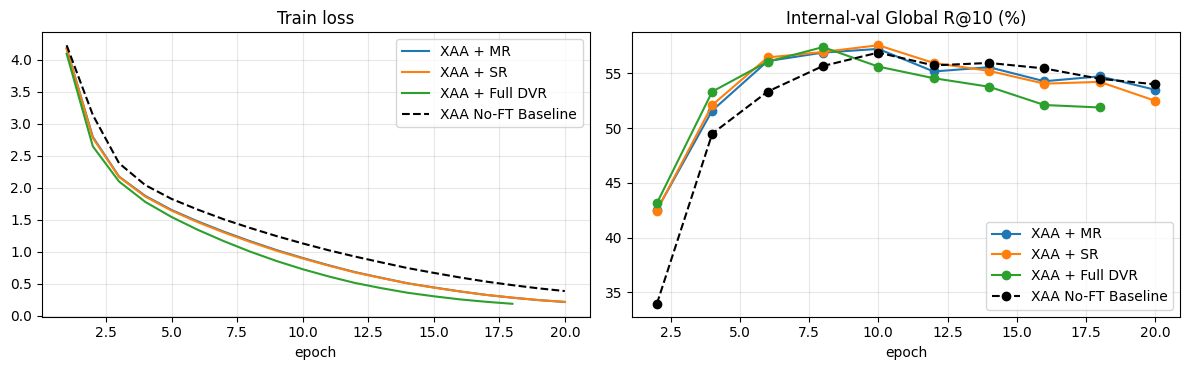

In [ ]:
from IPython.display import display

def load_results():
    R, H = {}, {}
    if BASELINE["status"] == "ok":
        R["baseline"], H["baseline"] = BASELINE["result"], BASELINE["hits"]
    for name in EXPERIMENTS:
        P = exp_paths(name)
        if os.path.exists(P["metrics"]):
            with open(P["metrics"]) as f: R[name] = json.load(f)
            if os.path.exists(P["hits"]):
                z = np.load(P["hits"]); H[name] = dict(hitA=z["hitA"], hitB=z["hitB"])
    return R, H
RES, HITS = load_results()
LABELS = {"baseline": "XAA No-FT Baseline", **{k: v["label"] for k, v in EXPERIMENTS.items()}}
ORDER = ["baseline"] + list(EXPERIMENTS)

# ---- kiểm tra giao thức giống nhau giữa mọi kết quả đang có ----
for k, r in RES.items():
    if k == "baseline": continue
    check(r["n_final_test"] == len(FINAL["df_test"]) and r["provenance"]["gallery_sha"] == FINAL["gallery_sha"], f"{k}: query/gallery khác harness hiện tại")
    check(r["provenance"]["split_sha"] == SPLIT_SHA and r["provenance"]["target_id2idx_sha"] == TGT_MAP_SHA, f"{k}: split/feature mapping khác")
    check(r["provenance"]["xaa_init_hash"] == (BASELINE.get("result", {}).get("provenance", {}).get("init_hash") or r["provenance"]["xaa_init_hash"]),
          f"{k}: init hash phần XAA khác baseline")

NR = "Not Run"
def summary_table():
    rows = []
    for k in ORDER:
        if k in RES:
            r = RES[k]; rows.append({"Model": LABELS[k], "Global R@10": r["global"]["R@10"], **{f"Macro R@{x}": r["macro"][f"R@{x}"] for x in KS}})
        else:
            rows.append({"Model": LABELS[k] + (" (unavailable)" if k == "baseline" else ""), "Global R@10": NR, **{f"Macro R@{x}": NR for x in KS}})
    return pd.DataFrame(rows)
tbl = summary_table()
display(tbl.style.format(lambda v: f"{v:.2f}" if isinstance(v, float) else v).hide(axis="index"))

# bảng theo category (Protocol B) — R@10 và R@50
rows = []
for k in ORDER:
    if k in RES: rows.append({"Model": LABELS[k], **{f"{c} R@{x}": RES[k]["per_category"][c][f"R@{x}"] for c in CATS for x in (10, 50)}})
if rows: display(pd.DataFrame(rows).style.format(precision=2).hide(axis="index"))

# đường cong training (internal-val R@10) của các biến thể đã train
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k in EXPERIMENTS:
    hp = exp_paths(k)["hist"]
    if os.path.exists(hp):
        h = pd.read_csv(hp)
        ax[0].plot(h["epoch"], h["train_loss"], label=LABELS[k]); e = h.dropna(subset=["val_R@10"]); ax[1].plot(e["epoch"], e["val_R@10"], marker="o", label=LABELS[k])
if BASELINE["status"] == "ok" and os.path.exists(f"{BASELINE_DIR}/training_history.json"):
    bh = json.load(open(f"{BASELINE_DIR}/training_history.json"))
    ax[0].plot(range(1, len(bh["train_loss"]) + 1), bh["train_loss"], "k--", label="XAA No-FT Baseline")
    ax[1].plot([e["epoch"] for e in bh["eval"]], [e["R@10"] for e in bh["eval"]], "k--", marker="o", label="XAA No-FT Baseline")
ax[0].set_title("Train loss"); ax[1].set_title("Internal-val Global R@10 (%)")
for a in ax:
    a.grid(alpha=.3); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 18. Delta Comparison

`Δ = Metric(DVR variant) − Metric(XAA No-FT Baseline)` — đơn vị **điểm phần trăm (pp)**, *không* phải tăng tương đối.

Vì mỗi cấu hình chỉ train **1 seed**, notebook bổ sung khoảng tin cậy 95% **paired bootstrap trên tập final query** (cùng query cho cả hai model). CI này phản ánh *nhiễu lấy mẫu của tập test*, **không** phản ánh biến thiên giữa các seed huấn luyện — nên chênh lệch nhỏ cần được diễn giải thận trọng.

In [ ]:
CAT_KEYS = CATS
def delta_value(var, base, getter):
    return getter(RES[var]) - getter(RES[base])

def paired_bootstrap(a, b, n_boot=2000, seed=0, k=10):
    # Δ = a − b trên Recall@k: (Global, Protocol A) và (Macro, Protocol B). Resample query (macro: trong từng category).
    j = KS.index(k)
    dA = HITS[a]["hitA"][:, j].astype(float) - HITS[b]["hitA"][:, j].astype(float)
    dB = HITS[a]["hitB"][:, j].astype(float) - HITS[b]["hitB"][:, j].astype(float)
    cats = FINAL["q_cats"]; cidx = [np.where(cats == c)[0] for c in CATS]; N = len(dA)
    rng = np.random.RandomState(seed); gl, mc = np.empty(n_boot), np.empty(n_boot)
    for t in range(n_boot):
        gl[t] = dA[rng.randint(0, N, N)].mean() * 100
        mc[t] = np.mean([dB[ix[rng.randint(0, len(ix), len(ix))]].mean() for ix in cidx]) * 100
    ci = lambda x: (float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5)))
    return {"global": (float(dA.mean() * 100),) + ci(gl), "macro": (float(np.mean([dB[ix].mean() for ix in cidx]) * 100),) + ci(mc)}

def verdict(pt, lo, hi):
    if lo > 0: return "cải thiện (CI95% > 0)"
    if hi < 0: return "giảm (CI95% < 0)"
    return "chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0)"

BOOT = {}
if "baseline" in RES:
    rows = []
    for k in EXPERIMENTS:
        if k not in RES or k not in HITS:
            rows.append({"Model": LABELS[k], "Δ Global R@10": NR, "Δ Macro R@10": NR, "Δ Macro R@50": NR, "Δ Macro R@10 CI95%": NR}); continue
        BOOT[k] = paired_bootstrap(k, "baseline")
        rows.append({"Model": LABELS[k],
                     "Δ Global R@10": delta_value(k, "baseline", lambda r: r["global"]["R@10"]),
                     "Δ Macro R@10":  delta_value(k, "baseline", lambda r: r["macro"]["R@10"]),
                     "Δ Macro R@50":  delta_value(k, "baseline", lambda r: r["macro"]["R@50"]),
                     "Δ Macro R@10 CI95%": f"[{BOOT[k]['macro'][1]:+.2f}, {BOOT[k]['macro'][2]:+.2f}]"})
    dtbl = pd.DataFrame(rows)
    display(dtbl.style.format(lambda v: f"{v:+.2f}" if isinstance(v, float) else v).hide(axis="index"))
    # chi tiết: Δ theo từng metric & category
    rows = []
    for k in EXPERIMENTS:
        if k in RES:
            rows.append({"Model": LABELS[k], **{f"Δ Macro R@{x}": RES[k]["macro"][f"R@{x}"] - RES["baseline"]["macro"][f"R@{x}"] for x in KS},
                         **{f"Δ {c} R@{x}": RES[k]["per_category"][c][f"R@{x}"] - RES["baseline"]["per_category"][c][f"R@{x}"] for c in CATS for x in (10, 50)}})
    if rows: display(pd.DataFrame(rows).style.format(precision=2).hide(axis="index"))
else:
    print("⚠️ Không có baseline tương thích -> không tính Δ.", BASELINE.get("reasons"))

Model,Δ Global R@10,Δ Macro R@10,Δ Macro R@50,Δ Macro R@10 CI95%
XAA + MR,+0.51,+0.45,+0.14,"[-0.41, +1.32]"
XAA + SR,+0.59,+0.64,-0.09,"[-0.27, +1.56]"
XAA + Full DVR,+0.14,+0.23,-0.17,"[-0.74, +1.17]"


Model,Δ Macro R@1,Δ Macro R@5,Δ Macro R@10,Δ Macro R@50,Δ dress R@10,Δ dress R@50,Δ shirt R@10,Δ shirt R@50,Δ toptee R@10,Δ toptee R@50
XAA + MR,0.47,0.06,0.45,0.14,0.30,-0.30,-0.50,0.65,1.57,0.05
XAA + SR,0.45,0.18,0.64,-0.09,0.99,0.59,0.30,-0.25,0.63,-0.63
XAA + Full DVR,0.28,0.21,0.23,-0.17,0.59,0.00,-1.06,1.06,1.15,-1.57


In [ ]:
# ===== Nhận xét tự động (sinh từ số liệu thật; chỉ mô tả, không khẳng định ngoài phạm vi kiểm chứng) =====
def auto_analysis():
    done = [k for k in EXPERIMENTS if k in RES and k in BOOT]
    if "baseline" not in RES or not done:
        print("Chưa đủ dữ liệu (cần baseline hợp lệ + ít nhất một biến thể đã chạy)."); return
    out = []
    allk = ["baseline"] + done
    best = max(allk, key=lambda k: RES[k]["macro"]["R@10"])
    out.append(f"1. Macro Recall@10 cao nhất: {LABELS[best]} ({RES[best]['macro']['R@10']:.2f}%) — trong số: " +
               ", ".join(f"{LABELS[k]} {RES[k]['macro']['R@10']:.2f}" for k in allk) + ".")
    for i, (k, nm) in enumerate([("xaa_mr", "MR"), ("xaa_sr", "SR"), ("xaa_full_dvr", "Full DVR")], start=2):
        if k not in RES: out.append(f"{i}. {nm}: Not Run."); continue
        b = BOOT[k]
        out.append(f"{i}. {nm} vs No-FT: ΔMacro R@10 = {b['macro'][0]:+.2f} pp (CI95% [{b['macro'][1]:+.2f}, {b['macro'][2]:+.2f}]) → {verdict(*b['macro'])}; "
                   f"ΔGlobal R@10 = {b['global'][0]:+.2f} pp (CI95% [{b['global'][1]:+.2f}, {b['global'][2]:+.2f}]) → {verdict(*b['global'])}.")
    if all(k in HITS for k in ["xaa_mr", "xaa_sr", "xaa_full_dvr"]):
        for other, nm in [("xaa_mr", "MR Only"), ("xaa_sr", "SR Only")]:
            bb = paired_bootstrap("xaa_full_dvr", other)
            out.append(f"5. Full DVR vs {nm}: ΔMacro R@10 = {bb['macro'][0]:+.2f} pp (CI95% [{bb['macro'][1]:+.2f}, {bb['macro'][2]:+.2f}]) → {verdict(*bb['macro'])}.")
    else:
        out.append("5. Full DVR vs MR/SR Only: cần chạy đủ cả ba biến thể.")
    out.append("6. Theo category (Δ R@10 / Δ R@50, pp so với baseline):")
    for k in done:
        out.append("   - " + LABELS[k] + ": " + "; ".join(
            f"{c} {RES[k]['per_category'][c]['R@10'] - RES['baseline']['per_category'][c]['R@10']:+.2f}/{RES[k]['per_category'][c]['R@50'] - RES['baseline']['per_category'][c]['R@50']:+.2f}" for c in CATS))
    flags = []
    for k in done:
        d10 = RES[k]["macro"]["R@10"] - RES["baseline"]["macro"]["R@10"]; d50 = RES[k]["macro"]["R@50"] - RES["baseline"]["macro"]["R@50"]
        if d10 > 0 and d50 < 0: flags.append(f"{LABELS[k]} (Macro: R@10 {d10:+.2f}, R@50 {d50:+.2f})")
        for c in CATS:
            c10 = RES[k]["per_category"][c]["R@10"] - RES["baseline"]["per_category"][c]["R@10"]; c50 = RES[k]["per_category"][c]["R@50"] - RES["baseline"]["per_category"][c]["R@50"]
            if c10 > 0 and c50 < 0: flags.append(f"{LABELS[k]} / {c} (R@10 {c10:+.2f}, R@50 {c50:+.2f})")
    out.append("7. Trường hợp R@10 tăng nhưng R@50 giảm: " + ("; ".join(flags) if flags else "không có trong các biến thể đã chạy."))
    for k in done:
        ds = [RES[k]["global"][f"R@{x}"] - RES["baseline"]["global"][f"R@{x}"] for x in KS] + [RES[k]["macro"][f"R@{x}"] - RES["baseline"]["macro"][f"R@{x}"] for x in KS]
        npos, nneg = sum(d > 0 for d in ds), sum(d < 0 for d in ds)
        out.append(f"8. Nhất quán giữa các metric — {LABELS[k]}: {npos}/8 metric (Global+Macro × R@1/5/10/50) tăng, {nneg}/8 giảm → " +
                   ("nhất quán" if npos == 8 or nneg == 8 else "KHÔNG nhất quán giữa các metric"))
    out.append("⚠️ Lưu ý: mỗi cấu hình chỉ 1 seed; CI chỉ phản ánh nhiễu lấy mẫu tập test. Chênh lệch nhỏ chưa đủ để kết luận DVR hiệu quả.")
    print("\n".join(out))
auto_analysis()

1. Macro Recall@10 cao nhất: XAA + SR (34.63%) — trong số: XAA No-FT Baseline 33.99, XAA + MR 34.44, XAA + SR 34.63, XAA + Full DVR 34.22.
2. MR vs No-FT: ΔMacro R@10 = +0.45 pp (CI95% [-0.41, +1.32]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0); ΔGlobal R@10 = +0.51 pp (CI95% [-0.35, +1.34]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0).
3. SR vs No-FT: ΔMacro R@10 = +0.64 pp (CI95% [-0.27, +1.56]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0); ΔGlobal R@10 = +0.59 pp (CI95% [-0.30, +1.47]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0).
4. Full DVR vs No-FT: ΔMacro R@10 = +0.23 pp (CI95% [-0.74, +1.17]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0); ΔGlobal R@10 = +0.14 pp (CI95% [-0.88, +1.08]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0).
5. Full DVR vs MR Only: ΔMacro R@10 = -0.22 pp (CI95% [-1.09, +0.64]) → chưa phân biệt được với nhiễu lấy mẫu (CI95% chứa 0).
5. Full DVR vs SR Only: ΔMacro R@10 = -0.41 pp (CI95% [-1.22, +0.4

## 19. Gate Visualization (Optional)

Chỉ chạy nếu `IMAGES_DIR` tồn tại và biến thể đã được train. Với reference image có **1 CLS + 49 patch**, heatmap 7×7 chỉ dùng **49 patch không gian** (bỏ CLS). Màu: trắng ≈ gate 1 (không đổi), đỏ > 1 (khuếch đại), xanh < 1 (giảm). Phần này chỉ để phân tích — **không** ảnh hưởng metric hay chọn checkpoint. Cùng một bộ query cố định (seed) được dùng cho mọi model.

In [ ]:
import textwrap
def visualize_gates(name, n=4):
    if not (IMAGES_DIR and os.path.isdir(IMAGES_DIR)):
        print("[skip] IMAGES_DIR không tồn tại -> bỏ qua visualization."); return
    if not os.path.exists(exp_paths(name)["best"]):
        print(f"[skip] {name} chưa train."); return
    from PIL import Image
    prepare_final_eval(); model, _ = load_trained_model(name)
    pick = np.random.RandomState(SEED).choice(len(FINAL["df_test"]), n, replace=False)
    th = torch.from_numpy(FINAL["text_test"][pick]).to(device); tm = torch.from_numpy(FINAL["mask_test"][pick]).to(device)
    rh = torch.from_numpy(np.stack([np.asarray(ref_hidden[reference_id2idx[r]], dtype=np.float32) for r in FINAL["q_ref_ids"][pick]])).to(device)
    with torch.inference_mode(): emb, gates = model(th, tm, rh, return_gates=True)
    emb = np.ascontiguousarray(F.normalize(emb.float(), dim=-1).cpu().numpy())
    _, I = FINAL["global_index"].search(emb, 5)
    alpha = DVR_ALPHA
    fig, axes = plt.subplots(n, 9, figsize=(27, 3.1 * n))
    for r, qi in enumerate(pick):
        img = Image.open(f"{IMAGES_DIR}/{FINAL['q_ref_ids'][qi]}.jpg").convert("RGB"); W, H = img.size
        axes[r, 0].imshow(img); axes[r, 0].set_title("Reference", fontsize=9)
        axes[r, 1].text(0.5, 0.5, "\n".join(textwrap.wrap(FINAL["q_mods"][qi], 28)), ha="center", va="center", fontsize=8); axes[r, 1].set_title("Modification", fontsize=9)
        for col, key, ttl in [(2, "mr", "MR gate 7×7"), (3, "sr", "SR gate 7×7")]:
            a = axes[r, col]; a.set_title(ttl, fontsize=9)
            if key in gates:
                g = gates[key][r].detach().cpu().numpy(); check(g.shape[0] == 50, "gate không có 50 token")
                grid = g[1:].reshape(7, 7)                                  # bỏ CLS (index 0); chỉ 49 patch không gian
                a.imshow(img); im = a.imshow(grid, extent=(0, W, H, 0), cmap="coolwarm", vmin=1 - alpha, vmax=1 + alpha, alpha=0.55, interpolation="nearest")
                a.set_xlabel(f"mean|g-1|={np.abs(grid - 1).mean():.3f}", fontsize=8)
            else:
                a.text(0.5, 0.5, "off", ha="center", va="center", color="gray")
        for k_i, j in enumerate(I[r]):
            tid = FINAL["global_ids"][j]; ok = tid == FINAL["q_tgt_ids"][qi]; a = axes[r, 4 + k_i]
            a.imshow(Image.open(f"{IMAGES_DIR}/{tid}.jpg").convert("RGB")); a.set_title(f"Top-{k_i+1}" + (" ✓" if ok else ""), color="green" if ok else "red", fontsize=8)
        for a in axes[r]: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{LABELS[name]} — gate weights & top-5 (global gallery)", y=1.0)
    plt.tight_layout(); plt.savefig(f"{exp_paths(name)['dir']}/gate_visualization.png", dpi=110); plt.show()
    del model

for _k in EXPERIMENTS:
    if _k in RES: visualize_gates(_k)

[skip] IMAGES_DIR không tồn tại -> bỏ qua visualization.
[skip] IMAGES_DIR không tồn tại -> bỏ qua visualization.
[skip] IMAGES_DIR không tồn tại -> bỏ qua visualization.


## 20. Discussion and Limitations

**Về cách đọc kết quả**
* Chỉ so sánh với **XAA No-FT Baseline**; không có XAA FT, TME, target alignment hay auxiliary loss trong notebook này.
* Mỗi cấu hình chỉ được train với **một seed** (42). Chênh lệch giữa các biến thể có thể nằm trong biến thiên giữa các lần train; khoảng tin cậy bootstrap chỉ xét nhiễu lấy mẫu của tập final query. Muốn kết luận chắc hơn cần ≥3 seed cho mỗi cấu hình.
* Checkpoint được chọn **chỉ** bằng internal-validation Global R@10; final-test chỉ được dùng để báo cáo.
* Tập `excluded_final_overlap` (100 triplet) không tham gia final evaluation.

**Về thiết kế DVR**
* MR/SR là phiên bản *lấy cảm hứng từ FashionERN, điều chỉnh cho 50 image token của XAA* (gate vô hướng theo token + residual `V·(1+α·tanh(G))`, khởi tạo identity). **Không** phải tái hiện nguyên bản FashionERN; kết quả không thể quy cho bài báo gốc.
* Trong XAA, **query là text** và image chỉ đóng vai trò K/V; vì vậy refinement chỉ thay đổi *cách text “nhìn” ảnh*. Gate theo token có thể bị hạn chế khả năng thể hiện so với DVR dạng channel-wise/đa tầng của FashionERN.
* `α=1` cố định và `hidden=256` là lựa chọn thiết kế **không được tune** (để tránh dùng final-test chọn cấu hình); các giá trị này chưa được ablate.
* Số tham số tăng nhẹ khi bật MR/SR (xem mục 10); không thể tách hoàn toàn hiệu ứng “thêm tham số” khỏi hiệu ứng “refinement”.

**Về tái lập**
* Phần XAA chung có cùng init hash (được test); RNG toàn cục được khôi phục sau khi tạo MR/SR nên thứ tự shuffle/dropout của các biến thể cùng seed là như nhau. Nhưng cuDNN/GPU không đảm bảo bit-exact giữa các lần chạy.
* Resume từ `last_checkpoint.pt` là best-effort (DataLoader worker RNG không được khôi phục bit-exact).